# Notebook 1 · Section 0 : Inventaire technique et profilage
**Dataset :** Smart Meters in London (Kaggle, `jeanmidev/smart-meters-in-london`)

**Objectif :** connaître le volume réel, le schéma et la forme des fichiers avant toute analyse, sans modifier les données d'origine.

**Questions traitées :** combien de fichiers, de lignes et de foyers par bloc ? Quels types de colonnes ? Quel format de date ? Quelle stratégie de lecture pour 10 Go de CSV ?

**Prérequis :** télécharger et décompresser le dataset (par exemple avec l'API Kaggle : `kaggle datasets download -d jeanmidev/smart-meters-in-london -p data --unzip`), puis définir la variable d'environnement `LCL_DATA_DIR` si le dossier n'est pas `data/smart-meters-in-london`.


## Cellule 0 · Configuration et imports

In [3]:
import os, re, time
from pathlib import Path
import pandas as pd
import pyarrow as pa
import pyarrow.csv as pacsv
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import display

DATA_DIR = Path(os.environ.get("LCL_DATA_DIR", "../data"))
PARQUET_DIR = Path(os.environ.get("LCL_PARQUET_DIR", "data/parquet_raw"))
PARQUET_DIR.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)

assert DATA_DIR.exists(), f"Dossier introuvable : {DATA_DIR.resolve()} (voir les prérequis)"
print("Données lues depuis :", DATA_DIR.resolve())

Matplotlib is building the font cache; this may take a moment.


Données lues depuis : C:\ING_IDSD\3emeAnnee\MLOPS\GridPulse\data


## Cellule 1 · Inventaire des fichiers
On liste tous les fichiers, leur dossier et leur taille.

In [4]:
rows = []
for p in sorted(DATA_DIR.rglob("*")):
    if p.is_file():
        rel = p.relative_to(DATA_DIR)
        rows.append({
            "chemin": rel.as_posix(),
            "dossier": rel.parent.as_posix(),
            "extension": p.suffix.lower(),
            "taille_Mo": p.stat().st_size / 1e6,
        })
inventaire = pd.DataFrame(rows)

resume_dossiers = (inventaire.groupby("dossier")
                   .agg(fichiers=("chemin", "count"), taille_Mo=("taille_Mo", "sum"))
                   .round(1).sort_values("taille_Mo", ascending=False))
display(resume_dossiers)
print(f"Total : {len(inventaire)} fichiers, {inventaire.taille_Mo.sum() / 1000:.2f} Go")
print("Extensions présentes :", inventaire.extension.value_counts().to_dict())

,fichiers,taille_Mo
dossier,,
halfhourly_dataset/halfhourly_dataset,112,7865.7
hhblock_dataset/hhblock_dataset,112,1671.3
daily_dataset/daily_dataset,112,374.5
.,8,354.8


Total : 344 fichiers, 10.27 Go
Extensions présentes : {'.csv': 342, '.html': 1, '.xlsx': 1}


## Cellule 2 · Outils de lecture économes en mémoire
Compter les lignes sans charger les fichiers, et repérer les colonnes automatiquement (les noms exacts sont à confirmer).

In [5]:

def count_lines(path, bufsize=1 << 20):
    """Nombre de lignes de données (en-tête exclu), sans charger le fichier."""
    n = 0
    with open(path, "rb") as f:
        while True:
            chunk = f.read(bufsize)
            if not chunk:
                break
            n += chunk.count(b"\n")
    return max(n - 1, 0)


def natural_key(p):
    return [
        int(t) if t.isdigit() else t
        for t in re.split(r"(\d+)", Path(p).stem)
    ]


def csv_files(folder):
    return sorted(Path(folder).rglob("*.csv"), key=natural_key)


## Cellule 3 · Fichiers simples (métadonnées, météo, jours fériés)
Pour chaque CSV situé à la racine : nombre de lignes, colonnes, types lus et aperçu.

In [7]:

simple_csv = sorted(DATA_DIR.glob("*.csv"))
profil_simple = []

for p in simple_csv:
    n = count_lines(p)

    try:
        echantillon = pd.read_csv(
            p,
            nrows=2000,
            encoding="cp1252"
        )

        profil_simple.append({
            "fichier": p.name,
            "lignes": n,
            "colonnes": echantillon.shape[1]
        })

        print("=" * 100)
        print(f"{p.name} : {n:,} lignes, {echantillon.shape[1]} colonnes")
        print("Types inférés sur un échantillon :")
        print(echantillon.dtypes.astype(str).to_string())
        display(echantillon.head(3))

    except Exception as e:
        print(f"Erreur pour {p.name} : {e}")

display(pd.DataFrame(profil_simple))


acorn_details.csv : 826 lignes, 20 colonnes
Types inférés sur un échantillon :
MAIN CATEGORIES        str
CATEGORIES             str
REFERENCE              str
ACORN-A            float64
ACORN-B            float64
ACORN-C            float64
ACORN-D            float64
ACORN-E            float64
ACORN-F            float64
ACORN-G            float64
ACORN-H            float64
ACORN-I            float64
ACORN-J            float64
ACORN-K            float64
ACORN-L            float64
ACORN-M            float64
ACORN-N            float64
ACORN-O            float64
ACORN-P            float64
ACORN-Q            float64


,MAIN CATEGORIES,CATEGORIES,REFERENCE,ACORN-A,ACORN-B,ACORN-C,ACORN-D,ACORN-E,ACORN-F,ACORN-G,ACORN-H,ACORN-I,ACORN-J,ACORN-K,ACORN-L,ACORN-M,ACORN-N,ACORN-O,ACORN-P,ACORN-Q
0,POPULATION,Age,Age 0-4,77.0,83.0,72.0,100.0,120.0,77.0,97.0,97.0,63.0,119.0,67.0,114.0,113.0,89.0,123.0,138.0,133.0
1,POPULATION,Age,Age 5-17,117.0,109.0,87.0,69.0,94.0,95.0,102.0,106.0,67.0,95.0,64.0,108.0,116.0,86.0,89.0,136.0,106.0
2,POPULATION,Age,Age 18-24,64.0,73.0,67.0,107.0,100.0,71.0,83.0,89.0,62.0,104.0,459.0,97.0,96.0,86.0,117.0,109.0,110.0


daily_dataset.csv : 3,510,433 lignes, 9 colonnes
Types inférés sur un échantillon :
LCLid                str
day                  str
energy_median    float64
energy_mean      float64
energy_max       float64
energy_count       int64
energy_std       float64
energy_sum       float64
energy_min       float64


,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000131,2011-12-15,0.4850,0.432045,0.868,22,0.239146,9.505,0.072
1,MAC000131,2011-12-16,0.1415,0.296167,1.116,48,0.281471,14.216,0.031
2,MAC000131,2011-12-17,0.1015,0.189812,0.685,48,0.188405,9.111,0.064


informations_households.csv : 5,566 lignes, 5 colonnes
Types inférés sur un échantillon :
LCLid            str
stdorToU         str
Acorn            str
Acorn_grouped    str
file             str


...

weather_daily_darksky.csv : 882 lignes, 32 colonnes
Types inférés sur un échantillon :
temperatureMax                 float64
temperatureMaxTime                 str
windBearing                      int64
icon                               str
dewPoint                       float64
temperatureMinTime                 str
cloudCover                     float64
windSpeed                      float64
pressure                       float64
apparentTemperatureMinTime         str
apparentTemperatureHigh        float64
precipType                         str
visibility                     float64
humidity                       float64
apparentTemperatureHighTime        str
apparentTemperatureLow         float64
apparentTemperatureMax         float64
uvIndex                        float64
time                               str
sunsetTime                         str
temperatureLow                 float64
temperatureMin                 float64
temperatureHigh                float64
sunriseTime     

,temperatureMax,temperatureMaxTime,windBearing,icon,dewPoint,temperatureMinTime,cloudCover,windSpeed,pressure,apparentTemperatureMinTime,apparentTemperatureHigh,precipType,visibility,humidity,apparentTemperatureHighTime,apparentTemperatureLow,apparentTemperatureMax,uvIndex,time,sunsetTime,temperatureLow,temperatureMin,temperatureHigh,sunriseTime,temperatureHighTime,uvIndexTime,summary,temperatureLowTime,apparentTemperatureMin,apparentTemperatureMaxTime,apparentTemperatureLowTime,moonPhase
0,11.96,2011-11-11 23:00:00,123,fog,9.40,2011-11-11 07:00:00,0.79,3.88,1016.08,2011-11-11 07:00:00,10.87,rain,3.30,0.95,2011-11-11 19:00:00,10.87,11.96,1.0,2011-11-11 00:00:00,2011-11-11 16:19:21,10.87,8.85,10.87,2011-11-11 07:12:14,2011-11-11 19:00:00,2011-11-11 11:00:00,Foggy until afternoon.,2011-11-11 19:00:00,6.48,2011-11-11 23:00:00,2011-11-11 19:00:00,0.52
1,8.59,2011-12-11 14:00:00,198,partly-cloudy-day,4.49,2011-12-11 01:00:00,0.56,3.94,1007.71,2011-12-11 02:00:00,5.62,rain,12.09,0.88,2011-12-11 19:00:00,-0.64,5.72,1.0,2011-12-11 00:00:00,2011-12-11 15:52:53,3.09,2.48,8.59,2011-12-11 07:57:02,2011-12-11 14:00:00,2011-12-11 12:00:00,Partly cloudy throughout the day.,2011-12-12 07:00:00,0.11,2011-12-11 20:00:00,2011-12-12 08:00:00,0.53
2,10.33,2011-12-27 02:00:00,225,partly-cloudy-day,5.47,2011-12-27 23:00:00,0.85,3.54,1032.76,2011-12-27 22:00:00,10.33,rain,13.39,0.74,2011-12-27 14:00:00,5.52,10.33,0.0,2011-12-27 00:00:00,2011-12-27 15:57:56,8.03,8.03,10.33,2011-12-27 08:07:06,2011-12-27 14:00:00,2011-12-27 00:00:00,Mostly cloudy throughout the day.,2011-12-27 23:00:00,5.59,2011-12-27 02:00:00,2011-12-28 00:00:00,0.10


weather_hourly_darksky.csv : 21,165 lignes, 12 colonnes
Types inférés sur un échantillon :
visibility             float64
windBearing              int64
temperature            float64
time                       str
dewPoint               float64
pressure               float64
apparentTemperature    float64
windSpeed              float64
precipType                 str
icon                       str
humidity               float64
summary                    str


,visibility,windBearing,temperature,time,dewPoint,pressure,apparentTemperature,windSpeed,precipType,icon,humidity,summary
0,5.97,104,10.24,2011-11-11 00:00:00,8.86,1016.76,10.24,2.77,rain,partly-cloudy-night,0.91,Partly Cloudy
1,4.88,99,9.76,2011-11-11 01:00:00,8.83,1016.63,8.24,2.95,rain,partly-cloudy-night,0.94,Partly Cloudy
2,3.70,98,9.46,2011-11-11 02:00:00,8.79,1016.36,7.76,3.17,rain,partly-cloudy-night,0.96,Partly Cloudy


,fichier,lignes,colonnes
0,acorn_details.csv,826,20
1,daily_dataset.csv,3510433,9
2,informations_households.csv,5566,5
3,uk_bank_holidays.csv,25,2
4,weather_daily_darksky.csv,882,32
5,weather_hourly_darksky.csv,21165,12


## Cellule 4 · Dossiers de blocs (demi-horaire, journalier, hhblock)
Pour chaque dossier : nombre de fichiers, colonnes, et nombre total de lignes. Le comptage du dossier demi-horaire peut prendre plusieurs minutes.

In [8]:
dossiers_blocs = sorted({p.parent for p in DATA_DIR.rglob("*.csv") if p.parent != DATA_DIR})
profil_blocs = []
for d in dossiers_blocs:
    fichiers = csv_files(d)
    t0 = time.time()
    total = sum(count_lines(f) for f in fichiers)
    colonnes = pd.read_csv(fichiers[0], nrows=0).columns.tolist()
    profil_blocs.append({
        "dossier": d.relative_to(DATA_DIR).as_posix(),
        "fichiers": len(fichiers),
        "lignes_totales": total,
        "nb_colonnes": len(colonnes),
        "colonnes": colonnes if len(colonnes) <= 8 else colonnes[:4] + ["..."] + colonnes[-2:],
        "secondes": round(time.time() - t0, 1),
    })
    print(f"\n{d.name} : {len(fichiers)} fichiers, {total:,} lignes")
    display(pd.read_csv(fichiers[0], nrows=3))

profil_blocs = pd.DataFrame(profil_blocs)
display(profil_blocs)


daily_dataset : 112 fichiers, 3,510,433 lignes


,LCLid,day,energy_median,energy_mean,energy_max,energy_count,energy_std,energy_sum,energy_min
0,MAC000002,2012-10-12,0.1385,0.154304,0.886,46,0.196034,7.098,0.000
1,MAC000002,2012-10-13,0.1800,0.230979,0.933,48,0.192329,11.087,0.076
2,MAC000002,2012-10-14,0.1580,0.275479,1.085,48,0.274647,13.223,0.070



halfhourly_dataset : 112 fichiers, 167,817,021 lignes


,LCLid,tstp,energy(kWh/hh)
0,MAC000002,2012-10-12 00:30:00.0000000,0
1,MAC000002,2012-10-12 01:00:00.0000000,0
2,MAC000002,2012-10-12 01:30:00.0000000,0



hhblock_dataset : 112 fichiers, 3,469,352 lignes


,LCLid,day,hh_0,hh_1,hh_2,hh_3,hh_4,hh_5,hh_6,hh_7,hh_8,hh_9,hh_10,hh_11,hh_12,hh_13,hh_14,hh_15,hh_16,hh_17,hh_18,hh_19,hh_20,hh_21,hh_22,hh_23,hh_24,hh_25,hh_26,hh_27,hh_28,hh_29,hh_30,hh_31,hh_32,hh_33,hh_34,hh_35,hh_36,hh_37,hh_38,hh_39,hh_40,hh_41,hh_42,hh_43,hh_44,hh_45,hh_46,hh_47
0,MAC000002,2012-10-13,0.263,0.269,0.275,0.256,0.211,0.136,0.161,0.119,0.167,0.109,0.168,0.107,0.166,0.117,0.157,0.126,0.146,0.106,0.135,0.191,0.915,0.933,0.122,0.138,0.076,0.133,0.076,0.133,0.085,0.263,0.134,0.235,0.124,0.184,0.230,0.176,0.388,0.260,0.918,0.278,0.267,0.239,0.230,0.233,0.235,0.188,0.259,0.250
1,MAC000002,2012-10-14,0.262,0.166,0.226,0.088,0.126,0.082,0.123,0.083,0.120,0.079,0.121,0.075,0.124,0.073,0.125,0.070,0.130,0.108,0.196,0.346,0.524,0.076,0.129,0.667,0.230,0.220,0.163,0.091,0.170,0.110,0.110,0.121,0.099,0.157,0.093,0.371,0.386,1.085,1.075,0.956,0.821,0.745,0.712,0.511,0.231,0.210,0.278,0.159
2,MAC000002,2012-10-15,0.192,0.097,0.141,0.083,0.132,0.070,0.130,0.074,0.124,0.078,0.118,0.082,0.112,0.087,0.106,0.140,0.120,1.075,0.146,0.123,0.082,0.127,0.077,0.551,0.149,0.129,0.075,0.130,0.075,0.129,0.075,0.128,0.166,0.194,0.695,0.260,0.227,0.255,1.164,0.249,0.225,0.258,0.260,0.334,0.299,0.236,0.241,0.237


,dossier,fichiers,lignes_totales,nb_colonnes,colonnes,secondes
0,daily_dataset/daily_dataset,112,3510433,9,"[LCLid, day, energy_median, energy_mean, ..., ...",0.6
1,halfhourly_dataset/halfhourly_dataset,112,167817021,3,"[LCLid, tstp, energy(kWh/hh)]",10.7
2,hhblock_dataset/hhblock_dataset,112,3469352,50,"[LCLid, day, hh_0, hh_1, ..., hh_46, hh_47]",4.6


## Cellule 5 · Conversion des blocs demi-horaires en Parquet (données brutes, sans correction)
Pour travailler sur l'ensemble des blocs sans relire 10 Go de CSV à chaque fois, on convertit **une seule fois** en Parquet.

Toutes les colonnes sont conservées **en texte**, sans aucun nettoyage : la chaîne `Null` éventuelle dans la consommation reste visible et sera traitée en section 2.

In [9]:
def csv_to_parquet(src, dst):
    if dst.exists():
        return "déjà converti"
    noms = pd.read_csv(src, nrows=0).columns.tolist()
    options = pacsv.ConvertOptions(
        column_types={n: pa.string() for n in noms},   # tout en texte : rien n'est corrigé ici
        strings_can_be_null=False,
    )
    table = pacsv.read_csv(src, convert_options=options)
    dst.parent.mkdir(parents=True, exist_ok=True)
    pq.write_table(table, dst, compression="zstd")
    return "converti"

dossier_hh = next(d for d in dossiers_blocs if "halfhourly" in d.name.lower())
fichiers_hh = csv_files(dossier_hh)
t0 = time.time()
for f in fichiers_hh:
    csv_to_parquet(f, PARQUET_DIR / dossier_hh.name / (f.stem + ".parquet"))
print(f"{len(fichiers_hh)} blocs traités en {time.time() - t0:.0f} s")

112 blocs traités en 35 s


## Cellule 6 · Profil de chaque bloc demi-horaire
Lignes, foyers, bornes de dates et nombre de consommations `Null` par bloc. Les dates sont comparées en texte : cela suppose un format identique partout, ce que la cellule vérifie aussi.

In [10]:
parquets = sorted((PARQUET_DIR / dossier_hh.name).glob("*.parquet"), key=natural_key)
cols = pq.read_schema(parquets[0]).names
ID_COL = next(c for c in cols if c.lower() == "lclid")
TS_COL = next(c for c in cols if c.lower() == "tstp")
ENERGY_COL = next(c for c in cols if c.lower().startswith("energy"))
print("Colonnes détectées :", ID_COL, TS_COL, ENERGY_COL)

stats = []
for pf in parquets:
    t = pq.read_table(pf, columns=[ID_COL, TS_COL, ENERGY_COL]).to_pandas()
    stats.append({
        "bloc": pf.stem,
        "lignes": len(t),
        "foyers": t[ID_COL].nunique(),
        "tstp_min": t[TS_COL].min(),
        "tstp_max": t[TS_COL].max(),
        "longueur_tstp_distinctes": sorted(t[TS_COL].str.len().unique().tolist()),
        "energie_Null_ou_vide": int(t[ENERGY_COL].isin(["Null", ""]).sum()),
    })
stats_blocs = pd.DataFrame(stats)
stats_blocs["part_Null_%"] = (100 * stats_blocs["energie_Null_ou_vide"] / stats_blocs["lignes"]).round(3)
display(stats_blocs)

print(f"\nLignes totales : {stats_blocs.lignes.sum():,}")
print(f"Somme des foyers par bloc (un foyer peut apparaître dans plusieurs blocs) : {stats_blocs.foyers.sum():,}")
print(f"Part de consommations Null ou vides : {100 * stats_blocs.energie_Null_ou_vide.sum() / stats_blocs.lignes.sum():.3f} %")

Colonnes détectées : LCLid tstp energy(kWh/hh)


,bloc,lignes,foyers,tstp_min,tstp_max,longueur_tstp_distinctes,energie_Null_ou_vide,part_Null_%
0,block_0,1222670,50,2011-12-03 09:00:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.004
1,block_1,1515865,50,2011-12-21 09:30:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003
2,block_2,1488465,50,2011-12-07 11:30:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003
3,block_3,1379314,50,2011-12-21 14:30:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.004
4,block_4,1473176,50,2011-12-20 09:00:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003
...,...,...,...,...,...,...,...,...
107,block_107,1489537,50,2012-02-28 14:30:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003
108,block_108,1593470,50,2011-12-13 09:30:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003
109,block_109,1475865,50,2011-12-01 14:00:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003
110,block_110,1429526,50,2011-12-07 12:00:00.0000000,2014-02-28 00:00:00.0000000,[27],50,0.003



Lignes totales : 167,817,021
Somme des foyers par bloc (un foyer peut apparaître dans plusieurs blocs) : 5,566
Part de consommations Null ou vides : 0.003 %


## Cellule 7 · Visualisation : taille des blocs

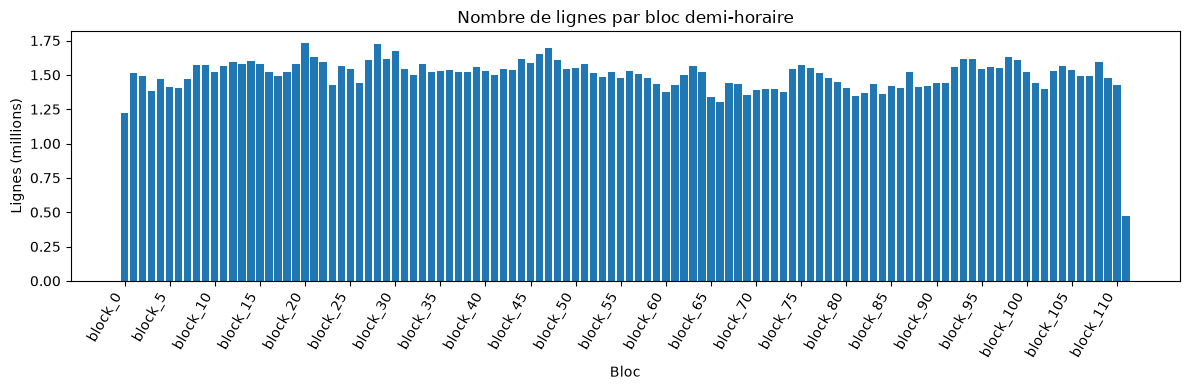

In [11]:
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(stats_blocs["bloc"], stats_blocs["lignes"] / 1e6)
ax.set_title("Nombre de lignes par bloc demi-horaire")
ax.set_xlabel("Bloc")
ax.set_ylabel("Lignes (millions)")
step = max(len(stats_blocs) // 20, 1)
ax.set_xticks(range(0, len(stats_blocs), step))
ax.set_xticklabels(stats_blocs["bloc"].iloc[::step], rotation=60, ha="right")
plt.tight_layout()
plt.show()

## Cellule 8 · Taille disque et stratégie de lecture

In [12]:
taille_csv = sum(f.stat().st_size for f in fichiers_hh) / 1e9
taille_parquet = sum(p.stat().st_size for p in parquets) / 1e9
print(f"CSV demi-horaire : {taille_csv:.2f} Go | Parquet : {taille_parquet:.2f} Go "
      f"(facteur de compression ≈ {taille_csv / taille_parquet:.1f})")

ram_par_bloc = stats_blocs.lignes.max() * 3 * 60 / 1e6   # ordre de grandeur : 3 colonnes texte de ~60 octets en pandas
print(f"Mémoire estimée pour charger le plus gros bloc en pandas : environ {ram_par_bloc:.0f} Mo (estimation grossière)")
print("Stratégie : lire les blocs Parquet un par un, agréger, puis concaténer les résultats agrégés.")

CSV demi-horaire : 7.87 Go | Parquet : 0.42 Go (facteur de compression ≈ 18.9)
Mémoire estimée pour charger le plus gros bloc en pandas : environ 312 Mo (estimation grossière)
Stratégie : lire les blocs Parquet un par un, agréger, puis concaténer les résultats agrégés.


## Cellule 9 · Synthèse de la section 0 (à compléter après exécution)

| Élément | Valeur observée |
|---|---|
| Nombre de fichiers (total) | |
| Nombre de blocs demi-horaires | |
| Lignes demi-horaires (total) | |
| Format des dates (`tstp`) et longueurs observées | |
| Part de consommations `Null` | |
| Colonnes de chaque fichier simple | |
| Écart avec la structure attendue | |

**Décisions possibles :**
- Lecture en Parquet bloc par bloc, ou PySpark si la mémoire est insuffisante.
- Vérifier le nombre de fichiers annoncé (19 selon la collègue) par rapport à l'inventaire.
- Passer à la section 1 : intégrité des clés et des jointures.